In [4]:
import os
from typing import TypedDict
from IPython.display import Markdown, Image, display
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_community.vectorstores import Chroma
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
from langchain.tools import tool
from langgraph.graph import StateGraph, END
from dotenv import load_dotenv

In [6]:
load_dotenv(override=True)

True

from langchain_community.document_loaders import PyPDFDirectoryLoader
# Path of all Documents : Abount AI Initiative
ai_initiative_pdf_paths = [ f"./resources/{file}" for file in os.listdir("./resources")]

In [7]:
# Creating PDF loader object
loader = PyPDFDirectoryLoader(path="./resources/")

In [12]:
from langchain_text_splitters import RecursiveCharacterTextSplitter
# Split Documents into chunks
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name="cl100k_base",
    chunk_size=1000,
    chunk_overlap=200
)
ai_initiative_chunks = loader.load_and_split(text_splitter=text_splitter)

In [15]:
### Step 4: Create Vector Store with Embeddings
from langchain_openai import OpenAIEmbeddings
from langchain_community.vectorstores import Chroma
# Initialize OpenAI embedding model
embedding_model = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")

vectorstore = Chroma.from_documents(
    documents=ai_initiative_chunks,
    embedding=embedding_model,
    collection_name="AI_Initiatives"
)

retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 10}
)

In [22]:
### Step 5: Test RAG Retrieval (Manual)
# Test query
test_query = "?"
print(f"🔍 Test Query: {test_query}")
print("=" * 80)

relevant_docs = retriever.invoke(test_query)
print(f"\nRetrieved {len(relevant_docs)} relevant chunks:\n")

for i, doc in enumerate(relevant_docs[:3], 1):
    print(f"📄 Result {i}:")
    print(f"  Source: {doc.metadata.get('source', 'Unknown')}")
    print(f"  Page: {doc.metadata.get('page', 'Unknown')}")
    print(f"  Content: {doc.page_content[:100]}...")
    print("-" * 80 + "\n")

🔍 Test Query: ?

Retrieved 1 relevant chunks:

📄 Result 1:
  Source: resources\cv.pdf
  Page: 0
  Content: AGOUZOUL Meryem
Étudiante en Master Intelligence Artificielle & Digital Computing (AIDC)
Recherche u...
--------------------------------------------------------------------------------



In [25]:
@tool
def retriever_tool(query: str) -> str:
    """Recherche des informations dans le CV (base de données privée de documents personnels).

    Utilisez cet outil pour répondre à toute question sur le parcours du candidat :
    - Formation, diplômes, établissements et années
    - Expériences professionnelles, stages et missions
    - Projets académiques et personnels (technologies utilisées, objectifs, résultats)
    - Compétences techniques (langages, frameworks, outils) et langues
    - Certifications, publications, activités associatives et centres d'intérêt
    - Coordonnées et informations de contact présentes dans le CV

    Args:
        query: Question en langage naturel sur le CV
               (p. ex. « Quels sont les projets de deep learning ? »,
               « Quelles sont les compétences en Python ? »,
               « Quelle est la formation actuelle ? »)

    Returns:
        str: Extraits pertinents du CV pour répondre à la question
    """
    try:
        relevant_document_chunks = retriever.invoke(query)
        context_list = [d.page_content for d in relevant_document_chunks]
        return "\n\n".join(context_list)
    except Exception as e:
        return f"Error querying CV database: {str(e)}"

In [26]:
model = ChatGoogleGenerativeAI(model="gemini-3.8-flash", temperature=0)
tools = [retriever_tool]
llm_with_tools = model.bind_tools(tools)

State and System message

In [27]:
import logging
from typing import Annotated, Sequence, Literal
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langchain.messages import SystemMessage, HumanMessage, AIMessage

In [29]:
# Configure logging to see agent's decision-making process
logging.basicConfig(
level=logging.INFO,
format=' %(asctime)s [%(levelname)s] %(message)s',
datefmt='%H:%M:%S'
)
logger = logging.getLogger(__name__)

In [30]:
class SimpleAgentState(TypedDict):
    """State for the agent: conversation history with message accumulation."""
    messages: Annotated[Sequence, add_messages]

In [31]:
agentic_rag_system_message = """
Vous êtes un assistant spécialisé dans l'analyse de CV. Vous répondez
aux questions sur le parcours, les compétences et les projets d'une personne
à partir des extraits de son CV, que vous obtenez avec l'outil de recherche.

Règles :
- Utilisez l'outil de recherche avant de répondre à toute question sur le CV.
- Répondez uniquement à partir des informations retrouvées. N'inventez rien
  et n'ajoutez pas d'informations externes.
- Ne mentionnez pas explicitement « le contexte » dans votre réponse.
- Soyez précis : citez les noms de projets, technologies, établissements et dates tels qu'ils apparaissent.
- Répondez dans la langue de la question.
- Si l'information n'est pas dans le CV, répondez : "Je ne sais pas - cette information
  n'est pas disponible dans le CV."
"""

Agent Node

In [32]:
def agent_node(state: SimpleAgentState) -> dict:
    """Agent node that calls the LLM with system prompt and current state."""
    logger.info("AGENT NODE: Processing request...")
    system_msg = SystemMessage(content=agentic_rag_system_message)
    messages = [system_msg] + list(state["messages"])

    logger.info("Calling LLM with tools...")
    response = llm_with_tools.invoke(messages)

    if hasattr(response, 'tool_calls') and response.tool_calls:
        logger.info(f"✓ Agent decided to use {len(response.tool_calls)} tool(s)")
        for i, tool_call in enumerate(response.tool_calls, 1):
            logger.info(f"  {i}. {tool_call['name']}")
    else:
        logger.info("  ✓ Agent generated final response (no tools needed)")

    return {"messages": [response]}

Condition de routage

In [33]:
def should_continue(state: SimpleAgentState) -> Literal["tools", "end"]:
    """Determines whether to continue to tools or end."""
    last_message = state["messages"][-1]
    if hasattr(last_message, 'tool_calls') and last_message.tool_calls:
        logger.info("🔀 ROUTING: Continuing to TOOLS node")
        return "tools"
    logger.info("ROUTING: Ending workflow (final response ready)")
    return "end"

creat, compile and display the Graph

In [34]:
workflow = StateGraph(SimpleAgentState)

original_tool_node = ToolNode(tools)

def tool_node_with_logging(state):
    logger.info("TOOL NODE: Executing tools...")
    result = original_tool_node.invoke(state)
    logger.info("Tools executed successfully")
    return result

workflow.add_node("agent", agent_node)
workflow.add_node("tools", tool_node_with_logging)
workflow.set_entry_point("agent")

 16:47:37 [INFO] ✅ Enhanced agent created successfully



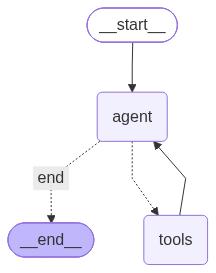

In [35]:
# Add conditional edge from agent
workflow.add_conditional_edges(
"agent",
should_continue,
{
"tools": "tools",
"end": END
}
)
# Add edge from tools back to agent
workflow.add_edge("tools", "agent")
graph = workflow.compile()
logger.info("✅ Enhanced agent created successfully\n")
display(Image(graph.get_graph().draw_mermaid_png()))

Tester l'application Agentic RAG

In [ ]:
print("="*80)
print("TEST 5: Enhanced Agent with RAG - AI Research Activity Check")
print("="*80 + "\n")
# Test query that requires AI research information
query = "Provide a comprehensive investment analysis for NVIDIA (NVDA) and Google including their AI research initiatives"
print(f"Query: {query}\n")
print("-"*80 + "\n")
result = graph.invoke(
{"messages": [HumanMessage(content=query)]}
)
print("\n🤖 ENHANCED AGENT RESPONSE (with RAG):")
print("="*80)
print(display(Markdown(result["messages"][-1].content)))
print("\n" + "="*80)
print("\n✅ Notice: The agent now includes:")
print(" • AI research projects from private analyst reports")
print(" • Specific AI initiative details")
print(" • Integration of financial + AI research data")
print(" • Comprehensive investment recommendation")

 20:39:28 [INFO] AGENT NODE: Processing request...
 20:39:28 [INFO] Calling LLM with tools...


TEST 5: Enhanced Agent with RAG - AI Research Activity Check

Query: Provide a comprehensive investment analysis for NVIDIA (NVDA) and Google including their AI research initiatives

--------------------------------------------------------------------------------



 20:39:30 [INFO] HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.8-flash:generateContent "HTTP/1.1 503 Service Unavailable"
 20:39:30 [INFO] Retrying google.genai._api_client.BaseApiClient._request_once in 1.14 seconds as it raised ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}.
